# Seleção e diagnóstico da série (Níger)
**Variável:** inflação alimentar mensal, `inflacao_alimentar_log_pct` = 100·Δln(IPC alimentar).

**Escolha do país:** o Níger é um dos países com maior peso da agricultura no PIB (≈ 38 %) e menor rendimento da amostra, o que o torna particularmente exposto a choques sobre a produção alimentar. A série está completa e apresenta sazonalidade anual marcada, adequada à modelização SARIMA.

In [18]:
#%pip install pandas matplotlib statsmodels

In [19]:
import pandas as pd

url = ('https://raw.githubusercontent.com/leandromicael123/Aquecimento-global/'
       'Primeira-parte/dados/processados/painel_longo.csv')
painel = pd.read_csv(url, parse_dates=['data'])

niger = painel[painel['pais_iso3'] == 'NER'].set_index('data').sort_index()
serie = niger['inflacao_alimentar_log_pct']

print('Frequência inferida:', pd.infer_freq(serie.index))
print('Datas duplicadas:', serie.index.duplicated().sum())
print('Valores em falta:', serie.isna().sum())
print('Início:', serie.index.min().date(), '| Fim:', serie.index.max().date(), '| n =', len(serie))

Frequência inferida: MS
Datas duplicadas: 0
Valores em falta: 0
Início: 2000-02-01 | Fim: 2025-12-01 | n = 311


C:\Users\pedro\AppData\Local\Temp\ipykernel_21568\3304657497.py:10: Pandas4Warning: A future version of pandas will return a BaseOffset object instead of a string from infer_freq. Use pd.set_option('future.infer_freq_returns_offset', True) to get the future behavior, or set to False to keep the old behavior and silence this warning. To preserve the string representation, use ``infer_freq(...).freqstr``.
  print('Frequência inferida:', pd.infer_freq(serie.index))


A série é mensal e regular (frequência `MS`), sem datas duplicadas nem valores em falta: 311 observações, de fev/2000 a dez/2025. Começa em fevereiro porque a primeira diferença do log perde a observação inicial.

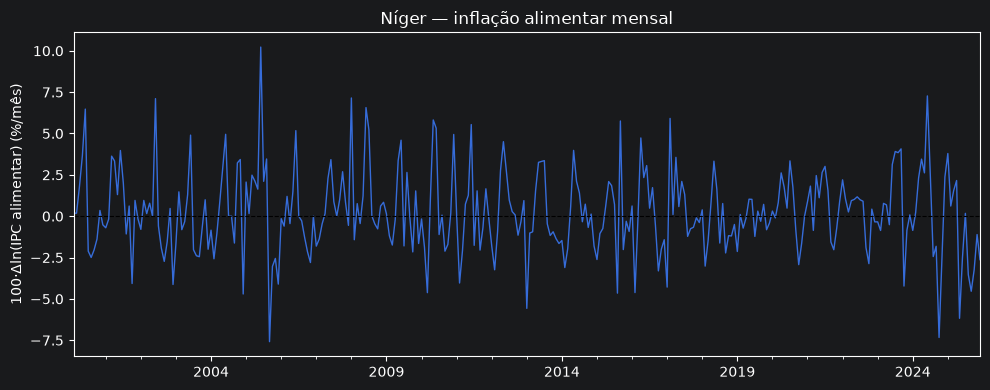

In [20]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
serie.plot(ax=ax, linewidth=1)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_title('Níger — inflação alimentar mensal')
ax.set_xlabel('')
ax.set_ylabel('100·Δln(IPC alimentar) (%/mês)')
plt.tight_layout()
plt.show()

Não se observa tendência: a série oscila em torno de um nível constante (média ≈ 0,24 %/mês). Os valores extremos concentram-se em 2005 (máximo de +10,2 em junho e mínimo de −7,6 em setembro) e em 2024. A amplitude das oscilações é menor entre 2019 e 2022 e volta a aumentar em 2024, o que sugere variância não constante.

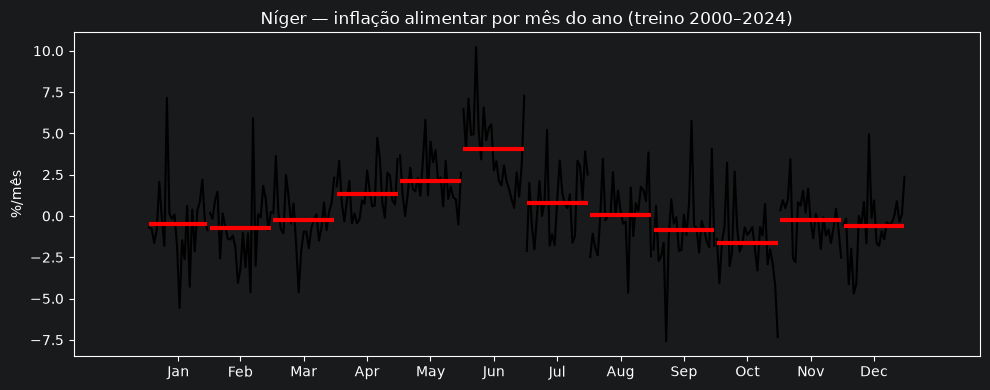

In [21]:
from statsmodels.graphics.tsaplots import month_plot

treino = serie[niger['amostra_temporal'] == 'treino_ate_2024']

fig, ax = plt.subplots(figsize=(10, 4))
month_plot(treino, ax=ax)
ax.set_title('Níger — inflação alimentar por mês do ano (treino 2000–2024)')
ax.set_ylabel('%/mês')
plt.tight_layout()
plt.show()

O gráfico sazonal por mês (`month_plot`), nos dados de treino, mostra sazonalidade anual: a inflação sobe de março a junho (máximo em junho, ≈ 4 %/mês) e desce de julho a outubro (mínimo em outubro, ≈ −1,7 %/mês). Com dados mensais, o período sazonal é s = 12.

In [22]:
treino = serie[niger['amostra_temporal'] == 'treino_ate_2024']
teste  = serie[niger['amostra_temporal'] == 'teste_2025']

print('Treino:', treino.index.min().date(), '→', treino.index.max().date(), '| n =', len(treino))
print('Teste: ', teste.index.min().date(),  '→', teste.index.max().date(),  '| n =', len(teste))

Treino: 2000-02-01 → 2024-12-01 | n = 299
Teste:  2025-01-01 → 2025-12-01 | n = 12


Os últimos 12 meses (jan–dez 2025) ficam reservados para teste e não são usados na seleção dos modelos. O treino tem 299 observações (fev/2000–dez/2024). Todas as decisões seguintes usam apenas o treino.

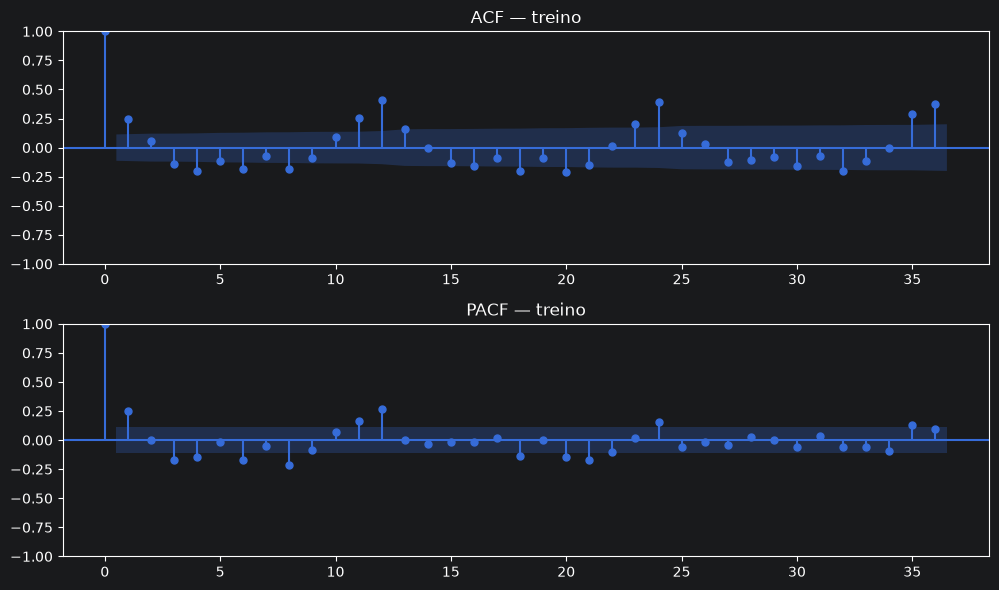

In [23]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
plot_acf(treino, lags=36, ax=ax[0])
ax[0].set_title('ACF — treino')
plot_pacf(treino, lags=36, ax=ax[1], method='ywm')
ax[1].set_title('PACF — treino')
plt.tight_layout()
plt.show()

In [24]:
from statsmodels.tsa.stattools import adfuller, kpss

adf1 = adfuller(treino, autolag='AIC', regression='c')
adf1_result = pd.Series(adf1[0:4], index=['ADF Test Statistic', 'P-Value',
                                          '# Lags Used', '# Observations Used'])
print(adf1_result)

kpss1 = kpss(treino, regression='c', nlags='auto')
kpss1_result = pd.Series(kpss1[0:3], index=['KPSS Test Statistic', 'P-Value', '# Lags Used'])
print(kpss1_result)

ADF Test Statistic      -3.835238
P-Value                  0.002567
# Lags Used             11.000000
# Observations Used    287.000000
dtype: float64
KPSS Test Statistic    0.031946
P-Value                0.100000
# Lags Used            1.000000
dtype: float64


C:\Users\pedro\AppData\Local\Temp\ipykernel_21568\2517821696.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf1 = adfuller(treino, autolag='AIC', regression='c')
C:\Users\pedro\AppData\Local\Temp\ipykernel_21568\2517821696.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss1 = kpss(treino, regression='c', nlags='auto')
C:\Users\pedro\AppData\Local\Temp\ipykernel_21568\2517821696.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In releas

Nos primeiros lags, a ACF decai rapidamente. O ADF rejeita a raiz unitária (p < 0,05) e o KPSS não rejeita a estacionaridade (p ≥ 0,10), pelo que não é necessária diferenciação simples (d = 0). A série já está em logaritmo e diferenciada, por isso não se aplica outra transformação.

Contudo, a ACF decai muito lentamente nos lags sazonais (≈ 0,41, 0,39 e 0,38 nos lags 12, 24 e 36), sinal de não estacionaridade sazonal. Estes testes avaliam a raiz unitária simples, não a sazonal.

C:\Users\pedro\AppData\Local\Temp\ipykernel_21568\1198025666.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf2 = adfuller(treino_d12, autolag='AIC', regression='n')


ADF Test Statistic    -6.330243e+00
P-Value                1.828602e-09
# Lags Used            1.100000e+01
# Observations Used    2.750000e+02
dtype: float64


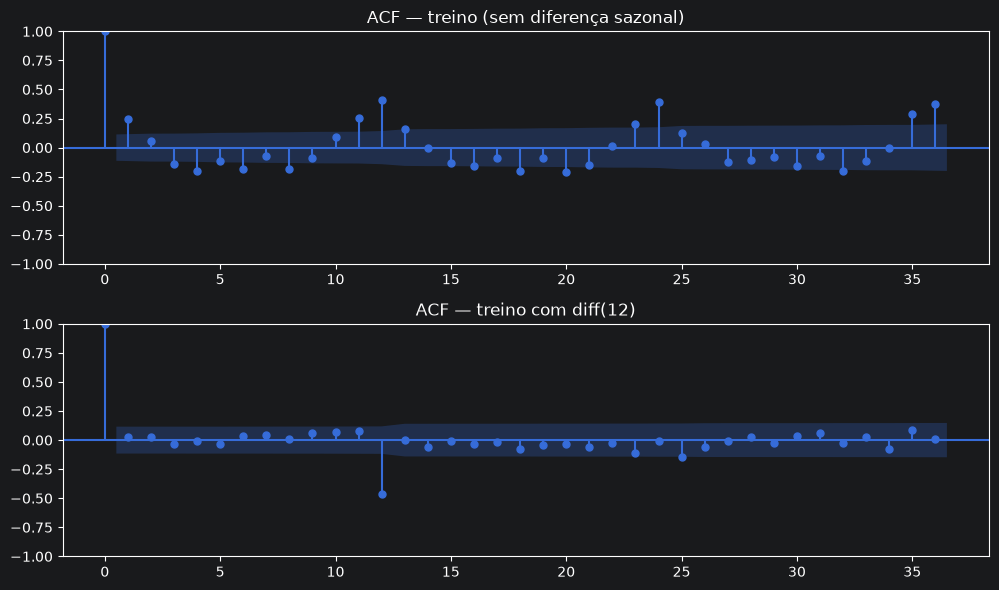

In [25]:
treino_d12 = treino.diff(12).dropna()

adf2 = adfuller(treino_d12, autolag='AIC', regression='n')
adf2_result = pd.Series(adf2[0:4], index=['ADF Test Statistic', 'P-Value',
                                          '# Lags Used', '# Observations Used'])
print(adf2_result)

fig, ax = plt.subplots(2, 1, figsize=(10, 6))
plot_acf(treino, lags=36, ax=ax[0])
ax[0].set_title('ACF — treino (sem diferença sazonal)')
plot_acf(treino_d12, lags=36, ax=ax[1])
ax[1].set_title('ACF — treino com diff(12)')
plt.tight_layout()
plt.show()

Após a diferença sazonal, as autocorrelações nos lags 24 e 36 deixam de ser significativas e o ADF rejeita a raiz unitária (p < 0,001). Adota-se **D = 1, d = 0 e s = 12**.

Resta um pico negativo isolado no lag 12 (≈ −0,47), o que sugere uma componente MA sazonal de ordem 1 (Q = 1). Candidato inicial para a secção 4.2: SARIMA(p,0,q)(0,1,1)₁₂.